# 电商客户聚类：全流程分析（Online Retail）

> **流程**：EDA 数据探索 → 数据清洗 → RFM 特征工程 → 特征变换 → K-means / DBSCAN 聚类 → 对比评估 → 业务结论
>
> **数据**：`../data/OnlineRetail.csv`（541,909 行 × 8 列，2010-12-01 ~ 2011-12-09，latin-1 编码）
>
> **运行**：从上到下逐 Cell 执行（Shift + Enter），带 ⚙️ 标记的 Cell 可修改参数后重跑。

---

## 1. 环境与配置

In [1]:
# ========== 第 1 步：导入需要用到的库 ==========
# 「库」= 别人写好的功能包，import 后就能直接调用
import pandas as pd       # pandas：处理表格数据（DataFrame，类似 Excel 表格）
import numpy as np        # numpy：数值计算（数组、数学函数，如对数变换 log1p）
import matplotlib.pyplot as plt   # matplotlib：最基础的绘图库，负责画图与显示
import seaborn as sns     # seaborn：基于 matplotlib 的高级统计绘图，一行代码画出好看的图

# sklearn = scikit-learn：Python 最流行的机器学习库，按功能拆成多个子模块导入
from sklearn.preprocessing import StandardScaler   # 标准化器：把数据变成「均值0、标准差1」
from sklearn.cluster import KMeans, DBSCAN         # 两种聚类算法（自动把客户分组）
from sklearn.decomposition import PCA              # PCA 主成分分析：降维，压到 2D 方便画图
from sklearn.manifold import TSNE                  # TSNE：另一种降维方法，专长可视化
from sklearn.neighbors import NearestNeighbors     # 找每个点的最近邻居，用于给 DBSCAN 选参数 eps
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score  # 3 个聚类质量评估指标

# 全局绘图风格：whitegrid=白色背景+网格线，muted=柔和配色（对所有图生效）
sns.set_theme(style="whitegrid", palette="muted")

# 解决 macOS 中文字体乱码（方块字）：matplotlib 默认的 Arial 不含中文字符
# 以下均为 macOS 自带的支持中文的字体，按优先级排列
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang HK", "Hiragino Sans GB", "Heiti TC", "Songti SC"]
plt.rcParams["axes.unicode_minus"] = False  # 让负号显示为正常的 "-"（而不是方块）

plt.rcParams["figure.figsize"] = (10, 5)  # 全局默认画布大小：宽10英寸、高5英寸
pd.set_option("display.max_columns", 50)  # 打印表格时最多显示 50 列，防止被省略号截断
# 打印浮点数统一显示「千分位+2位小数」，如 1234567.891 → 1,234,567.89
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")  # lambda = 匿名小函数，x 是每个要显示的数字
print("OK:", pd.__version__, np.__version__)  # 打印版本号，确认库都装好了

OK: 2.3.3 2.2.6


## 2. 加载数据

文件为 **latin-1 编码**（含 £ 等字符），必须指定 `encoding='latin-1'`。

In [2]:
# ========== 第 2 步：读取数据 ==========
DATA = "../data/OnlineRetail.csv"  # 数据文件路径（相对本 notebook 所在目录的上一级）
# pandas 读取 CSV；encoding="latin-1" 表示文件采用西欧字符编码（避免中文/特殊字符报错）
df = pd.read_csv(DATA, encoding="latin-1")
# 把 "InvoiceDate" 列从文本转为 datetime 时间类型，之后才能做取年月、算间隔等时间运算
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# f-string：字符串前加 f，大括号 {} 内可直接写变量或表达式；:,0f 表示千分位、0位小数
print(f"原始数据: {df.shape[0]:,} 行 × {df.shape[1]} 列")  # shape[0]=行数，shape[1]=列数
print(f"时间跨度: {df['InvoiceDate'].min()} ~ {df['InvoiceDate'].max()}")  # 最早 ~ 最晚交易时间
df.head()  # 查看前 5 行（Jupyter 会自动把 cell 最后一个表达式显示成表格）

原始数据: 541,909 行 × 8 列
时间跨度: 2010-12-01 08:26:00 ~ 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 3. EDA 数据探索

核心问题：数据是否干净？客户层面长什么样？为清洗与特征工程提供依据。

### 3.1 结构概览

In [3]:
# ========== 第 3 步：数据概览 ==========
df.info()  # 打印每列的类型、非空数量、内存占用（快速判断有无缺值、类型是否正确）
print()
print("各列唯一值数量：")
print(df.nunique())  # nunique() = number of unique，统计每列有多少个不同取值

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

各列唯一值数量：
InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64


### 3.2 缺失值

                缺失数  缺失占比%
Description    1454   0.27
CustomerID   135080  24.93


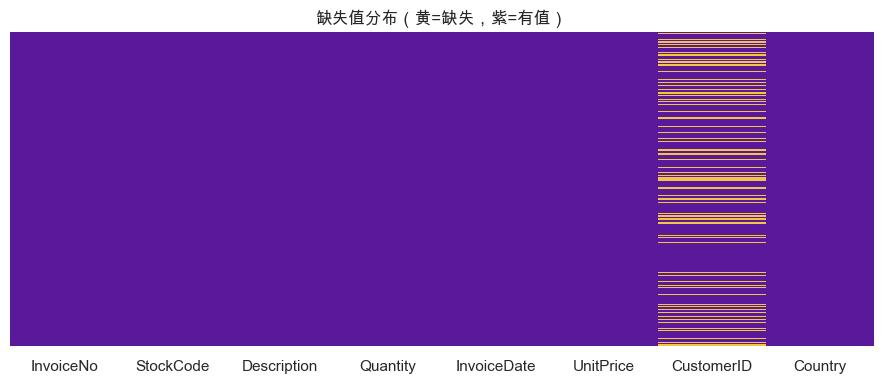

In [4]:
# ========== 检查缺失值 ==========
missing = df.isna().sum()  # isna() 返回 True/False 矩阵（True=该格为空），.sum() 按列求和 → 每列缺失数
miss_df = pd.DataFrame({"缺失数": missing, "缺失占比%": (missing / len(df) * 100).round(2)})  # 字典→表格，新增占比列
print(miss_df[miss_df["缺失数"] > 0])  # 布尔索引：只显示「缺失数>0」的行，其余忽略

# 缺失热力图（df.isna() 为布尔矩阵：False=有值、True=缺失）
# 双色显式映射：0(有值)=紫、1(缺失)=黄；Description 缺失仅 0.27%（1,454 行），行占比过低在图上几乎不可见
plt.figure(figsize=(9, 4))  # 新建一张 9×4 英寸的画布
sns.heatmap(df.isna(), cbar=False, cmap=["#5a189a", "#f4c542"], yticklabels=False)
# heatmap=热力图；cbar=False 不显示右侧颜色条；cmap=指定两种颜色；yticklabels=False 不显示每行标签
plt.title("缺失值分布（黄=缺失，紫=有值）")
plt.tight_layout()  # 自动调整边距，防止标题/坐标轴被裁掉
plt.show()  # 在输出区显示图形

### 3.3 时间维度

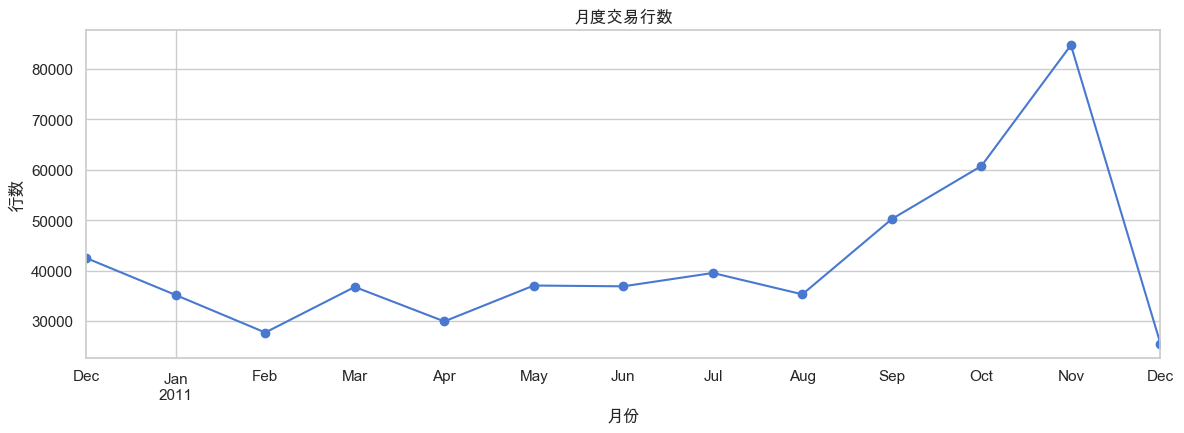

Month
2010-12    42481
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25525
Freq: M, dtype: int64

In [5]:
# ========== 按月份统计交易量（观察时间趋势） ==========
# .dt.to_period("M")：把每个时间点归到它所在的「月」；df["Month"] 是新增的一列
df["Month"] = df["InvoiceDate"].dt.to_period("M")
monthly = df.groupby("Month").size()  # groupby 按「月」分组，.size() 数每组有多少行
plt.figure(figsize=(12, 4.5))
monthly.plot(marker="o")  # 画折线图，marker="o" 表示在每个数据点上画圆点
plt.title("月度交易行数")
plt.xlabel("月份")
plt.ylabel("行数")
plt.tight_layout()
plt.show()
monthly  # 最后再单独显示月份统计结果，方便对照数字查看

In [6]:
# 观察窗口截止到 2011-12-09 → RFM 基准日取数据末日（见笔记「右截断」讨论）
print("数据末日（RFM 基准日）:", df["InvoiceDate"].max())

数据末日（RFM 基准日）: 2011-12-09 12:50:00


### 3.4 数值分布（Quantity / UnitPrice）

行级分布（每行 = 某订单里的某商品），用于字段清洗与 log 变换决策。**严重右偏**的判据：

- **定量**：均值 >> 中位数（Quantity 均值 10.66 / 中位数 3.00，UnitPrice 4.67 / 2.08）；
- **长尾**：最大值 Quantity 80,995、UnitPrice 38,970，远超 99 分位（100 / 18）。

原始直方图若不做截断，长尾会把坐标轴撑爆，99% 的数据挤成"贴 0 的一根线"、看不出形态——因此下图**截断到 99 分位**展示主体形态，完整统计量（均值/中位数/最大值）放在标题中佐证右偏。正数部分口径与下方 log1p 对比 cell 一致（负值/0 行为脏数据，见 3.6）。

**为什么直方图只画正数部分**（两个 cell 均用 `df[col] > 0` 过滤）：① `log1p` 对 ≤ -1 的值无定义（`log1p(-1) = -inf`、`log1p(-2) = NaN`），不过滤画图会出错；② Quantity 负值多为**退货 / C 取消单**（见 3.6），与正常购买是不同业务语义，混入会扭曲分布形态；③ 负值会拉低均值，让「均值 >> 中位数」的右偏判据失真。因此这里先按正数口径观察**有效交易**的分布，脏数据在 3.6 检查、第 4 节统一清洗。

**为什么后面要做对数变换（log1p）**：严重右偏会带来三个问题——① **可视性差**：长尾把坐标轴撑爆，主体形态看不清（上面的截断只是展示技巧，不改变数据）；② **建模不可靠**：若直接用原始值做聚类 / 距离计算，极端客户（Quantity 80,995）会主导距离，中位数 3 的普通客户被压得毫无区分度；③ **统计前提**：均值 / 方差等统计量对极端值敏感，许多方法更偏好近似对称的分布。

`log1p(x) = ln(1+x)` 是**单调递增**变换，恰好能同时缓解以上问题：**压缩长尾**让分布接近正态（便于读图与统计）、**保留样本间相对大小顺序**（单调性）、**缩小极端值影响**（避免大客户主导距离）。因此本项目第 6 节特征变换采用「log1p + 标准化」的组合，下方 log1p 对比图即验证其效果。


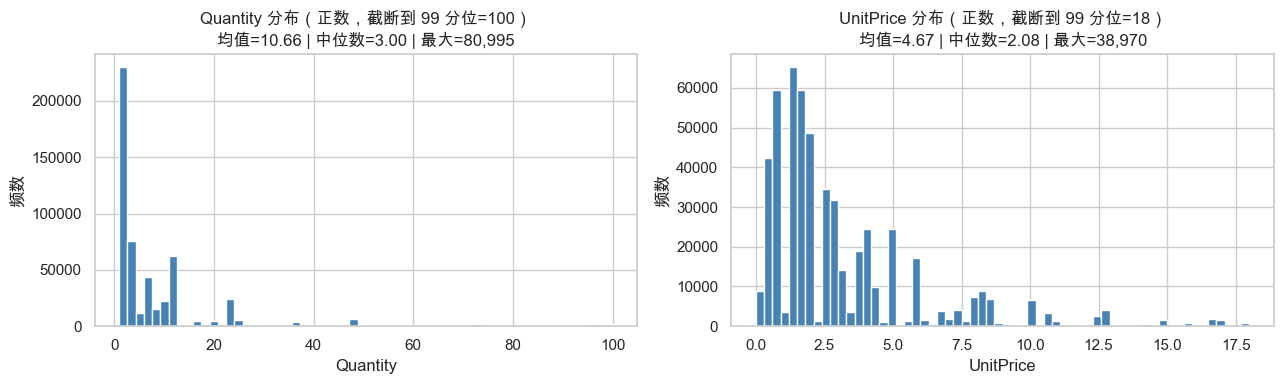

In [7]:
# ========== 行级 Quantity / UnitPrice 分布 ==========
# 只取正数部分（df[col] > 0）：负值为退货/C取消单等脏数据，先看「有效交易」的分布（详见 3.4 说明）
# 右偏判据：均值 >> 中位数（Quant 10.66/3.00、Price 4.67/2.08）+ 长尾最大 80,995/38,970
# 直方图截断到 99 分位（Quant=100、Price=18），避免长尾撑爆坐标轴；完整统计量留在标题佐证右偏
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # 一行两列子图：左=Quantity，右=UnitPrice
# zip(axes, [列名])：把两个子图与两列名一一配对；for 循环依次处理
for ax, col in zip(axes, ["Quantity", "UnitPrice"]):
    data = df[col][df[col] > 0]          # 布尔索引：取出该列中 >0 的行
    upper = data.quantile(0.99)          # 99 分位数：从小到大排序后第 99% 位置的值
    # 画直方图：只画 <= upper 的数据（截掉长尾）；bins=60 表示等分成 60 个柱子
    ax.hist(data[data <= upper], bins=60, color="steelblue", edgecolor="white")
    ax.set_title(                        # 标题用 f-string 嵌入统计量，佐证右偏
        f"{col} 分布（正数，截断到 99 分位={upper:,.0f}）\n"
        f"均值={data.mean():,.2f} | 中位数={data.median():,.2f} | 最大={data.max():,.0f}"
    )
    ax.set_xlabel(col)    # 横轴标签
    ax.set_ylabel("频数")  # 纵轴标签：落在每个区间内的行数
plt.tight_layout()
plt.show()

### 关于 log1p：对数变换 ≠ 归一化/标准化

上面解释了 log1p 的**动机**（压缩右偏、便于观察与建模）。这里再澄清一个常见误解——**log1p 并不是把两个横轴的量纲归一**：

- **作用对象不同**：归一化/标准化（如 `StandardScaler`）是**按列、跨样本**操作，把所有样本点拉到同一尺度（均值 0 / 方差 1，或 [0,1]）；而 `log1p` 是**按单列逐值**操作，只改变该列自身的分布形态，不改变样本间的相对大小顺序。
- **量纲差异依然存在**：`log1p(Quantity)` 与 `log1p(UnitPrice)` 的值域仍不相同（一个最大约 11，一个最大约 10），横轴之间仍不可直接比较。真正解决「天 / 次 / 元」量纲不可比问题的是**第 6 节的 `StandardScaler`**（`log1p` 在前、标准化在后，两者叠加使用）。
- **目的不同**：log 变换解决**分布偏态**，标准化解决**量纲统一**（聚类按欧氏距离对尺度敏感），两个步骤各司其职。

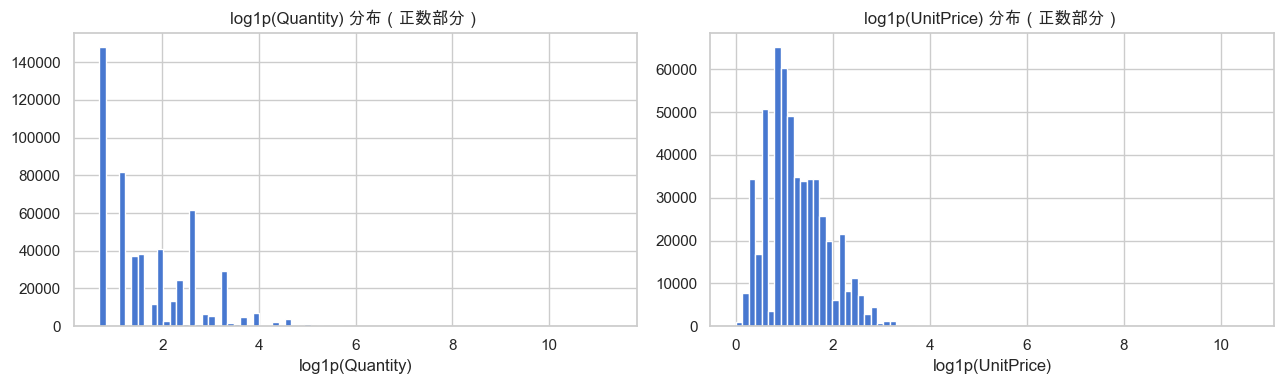

In [8]:
# ========== log1p 对数变换后的分布 ==========
# 目的：验证 log1p 能否把右偏长尾拉成近似正态（为第 6 节特征变换做准备，详见 3.4 说明）
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Quantity", "UnitPrice"]):
    pos = df[col][df[col] > 0]            # 同样只取正数部分（口径与上方一致）
    ax.hist(np.log1p(pos), bins=80)       # np.log1p(x)=ln(1+x)，逐元素变换后再画直方图
    ax.set_title(f"log1p({col}) 分布（正数部分）")
    ax.set_xlabel(f"log1p({col})")
plt.tight_layout()
plt.show()

### 3.4c 为什么 log1p 价值巨大（分布图看不出，距离计算才见真章）

上面两图**形状看起来差异不大**（都右偏）——因为 log1p 改变的是**横轴刻度**（对数刻度），不是形状。真正的价值在数据里，实测（Quantity 正数部分）：

| 指标 | 原始 | log1p 后 | 说明 |
|------|------|------|------|
| 偏度 skew | 460.1 | 1.03 | 极度右偏 → 接近对称 |
| 最大/中位数 | 26,998 倍 | 8.15 倍 | 长尾被压缩约 3000 倍 |
| 99 分位占最大值比例 | 0.1% | 40.8% | 变换前 99% 数据挤在最左端一根线 |

**最重要的价值：让聚类算法的距离公平**。KMeans/DBSCAN 靠欧氏距离分组，原始尺度下一个极端客户（Monetary 近 30 万）与普通客户（中位数 674）的距离，会主导普通客户之间的区分（主导度约 150 万倍），99% 的客户在聚类时被压成一个点；log1p 后主导度降到约 20 倍，普通客户之间重新有了区分度。

一句话：**log1p 把倍数关系变成大小关系**（乘法 → 加法/线性），让基于距离的聚类能同时公平地看待大客户和普通客户——这是截断坐标轴这类纯展示技巧替代不了的，也是第 6 节「log1p + 标准化」组合的前提。

### 3.4b 粒度对比：行级 → 订单级 → 客户级（补充）

上面的 3.4 看的是**行级**（每行 = 某订单里的某商品），那是为了检查字段本身。但"一次交易""一个客户"是不同粒度，分布形态差异很大：

| 粒度 | 每行代表 | 行数 | Quantity 均值 / 中位数 |
|------|---------|------|----------------------|
| 行级 | 某订单里的某商品 | 541,909 | 9.55 / 3 |
| 订单级（按 InvoiceNo 聚合） | 一次交易 | 25,900 | 199.9 / 100 |
| 客户级（按 CustomerID 聚合） | 一个客户（**RFM 粒度**） | 4,372 | 1,122.3 / 365 |

结论：**最终聚类看的是客户级**（第 5 节 RFM 正是这个粒度）；行级分布只用于字段清洗与 log 变换决策。

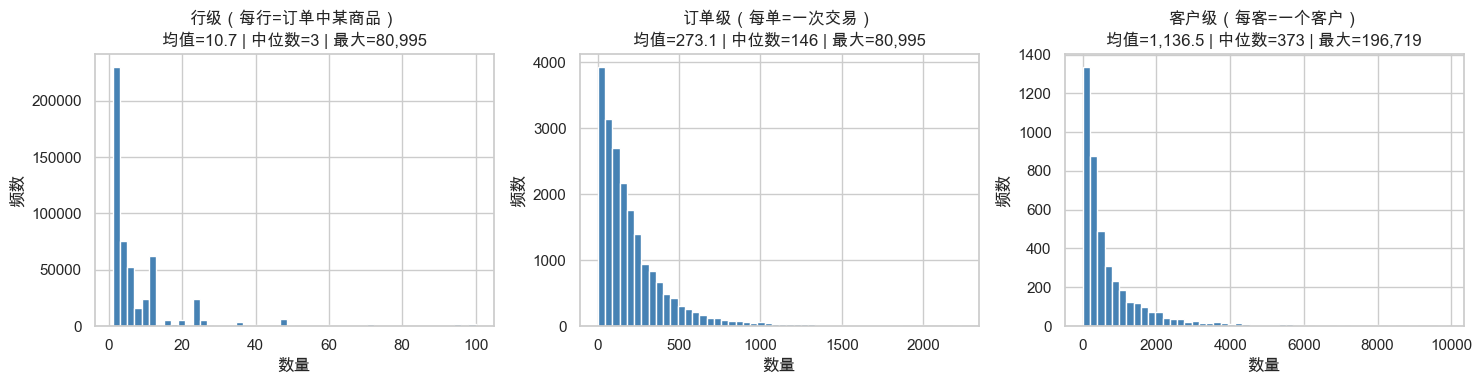

In [9]:
# ========== 三种粒度对比：行级 / 订单级 / 客户级 ==========
# 同样的 Quantity，统计口径不同分布差异很大（粒度越粗，数据越少、长尾越明显）
inv_qty = df.groupby("InvoiceNo")["Quantity"].sum()      # 订单级：按发票号分组，每单总件数
cust_qty = df.groupby("CustomerID")["Quantity"].sum()    # 客户级：按客户ID分组，每客累计件数

fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 一行三列子图
# datasets 是「(标题, 数据)」的列表，下方 for 循环逐个取出处理
datasets = [
    ("行级（每行=订单中某商品）", df["Quantity"][df["Quantity"] > 0]),
    ("订单级（每单=一次交易）", inv_qty[inv_qty > 0]),
    ("客户级（每客=一个客户）", cust_qty[cust_qty > 0]),
]
# for ax, (title, data) in zip(axes, datasets)：同时取出一个子图 ax 和一组 (标题, 数据)
for ax, (title, data) in zip(axes, datasets):
    upper = data.quantile(0.99)   # 同样截断到 99 分位，避免长尾撑爆坐标轴
    ax.hist(data[data <= upper], bins=50, color="steelblue", edgecolor="white")
    ax.set_title(f"{title}\n均值={data.mean():,.1f} | 中位数={data.median():,.0f} | 最大={data.max():,.0f}")
    ax.set_xlabel("数量")
    ax.set_ylabel("频数")
plt.tight_layout()
plt.show()

### 3.5 类别分布

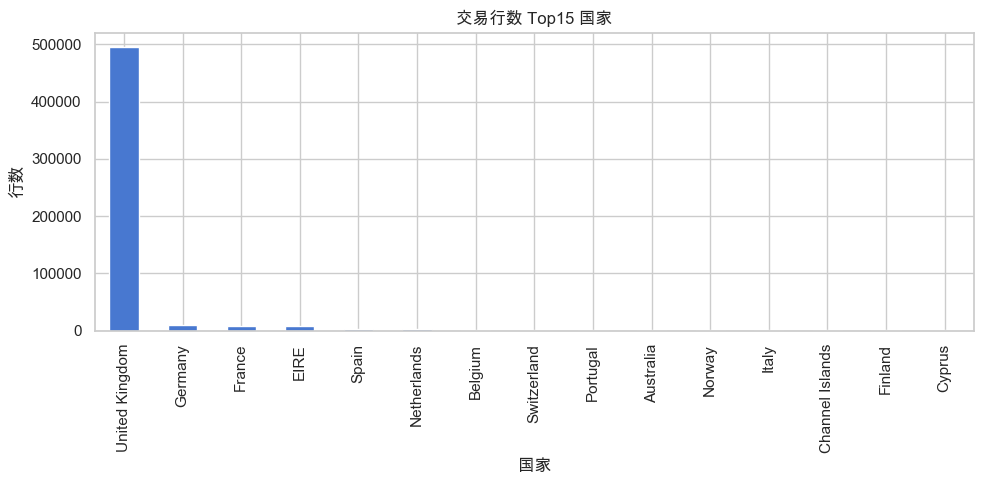

In [10]:
# ========== 国家分布 ==========
# value_counts()：统计该列每个取值出现的次数（默认降序排列）；.head(15) 只取前 15 名
# .plot(kind="bar")：画柱状图
df["Country"].value_counts().head(15).plot(kind="bar")
plt.title("交易行数 Top15 国家")
plt.xlabel("国家")
plt.ylabel("行数")
plt.tight_layout()
plt.show()

### 3.6 异常模式

聚类前必须看清的三类「脏」数据：负数量（退货）、负单价、C 开头取消单。

In [11]:
# ========== 异常模式检查（为 3.6 与第 4 节清洗提供依据） ==========
# 布尔比较 (df["Quantity"] < 0) 得到 True/False 序列，.sum() 把 True 累加成数字（True 计为 1）
print("负 Quantity 行数:", (df["Quantity"] < 0).sum())
print("零 UnitPrice 行数:", (df["UnitPrice"] == 0).sum())
print("负 UnitPrice 行数:", (df["UnitPrice"] < 0).sum())
# .astype(str)：把发票号转成文本；.str.startswith("C")：判断是否以字母 C 开头（C 开头=取消单）
print("C 开头取消单行数:", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("CustomerID 缺失:", df["CustomerID"].isna().sum())  # isna() 判断空值，sum() 计数

负 Quantity 行数: 10624
零 UnitPrice 行数: 2515
负 UnitPrice 行数: 2
C 开头取消单行数: 9288
CustomerID 缺失: 135080


### 3.7 客户初步视角

有效交易行数(仅剔 CustomerID 缺失+C 单): 397,924 | 有效客户数: 4,339


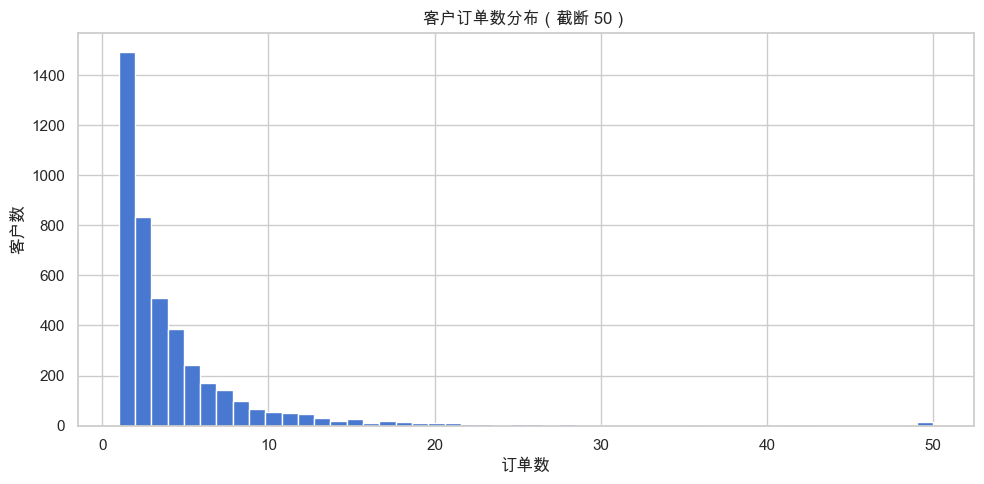

In [12]:
# ========== 3.5 有效交易口径（先剔除 2 类） ==========
# 口径提醒：这里只剔 CustomerID 缺失与 C 取消单（2 类），尚含 40 行 UnitPrice=0（31 个客户），
# 故 397,924 行 / 4,339 客户 ≠ 第 4 节清洗后「397,884 / 4,338」（4 类剔除），差值即这 40 行。
# notna()：非空；~：取反（True→False）；&：且（两个条件都要满足）
valid = df[df["CustomerID"].notna() & ~df["InvoiceNo"].astype(str).str.startswith("C")]
print("有效交易行数(仅剔 CustomerID 缺失+C 单):", f"{len(valid):,}", "| 有效客户数:", f"{valid['CustomerID'].nunique():,}")

# 每个客户的订单数：groupby 按客户分组，nunique() 数「不重复的发票号个数」
orders_per_cust = valid.groupby("CustomerID")["InvoiceNo"].nunique()
orders_per_cust.clip(upper=50).hist(bins=50)  # clip(upper=50)：超过 50 一律按 50 算（截断长尾）
plt.title("客户订单数分布（截断 50）")
plt.xlabel("订单数")
plt.ylabel("客户数")
plt.tight_layout()
plt.show()

### 3.8 EDA 小结（已核对实测）

> 下列数字均与上方各节实际输出核对一致。

- **数据规模**：541,909 行，跨度 373 天（2010-12-01 ~ 2011-12-09），**基准日 2011-12-09**；
- **缺失值**：`CustomerID` 缺失 24.9%（135,080 行）、`Description` 缺失 1,454 行；
- **分布形态**：`Quantity` / `UnitPrice` 严重右偏（均值 >> 中位数）→ 后续 **log1p + 标准化**；
- **异常模式**：负/零 Quantity 10,624 行、负/零 UnitPrice 2,517 行、C 取消单 9,288 行 → 第 4 节清洗剔除；
- **有效口径**：剔除上述后剩 **有效交易行 397,884**、有效订单 18,532、**有效客户 4,338**；
- **地域结构**：英国占 89%，绝对主导；
- **预期清洗结果**：去重后约 392,692 行（与第 4 节输出对照）。

---


## 4. 数据清洗

依据 EDA 结论，依次剔除：① CustomerID 缺失 ② 负/零 Quantity ③ 负/零 UnitPrice ④ 取消单。

In [13]:
# ========== 第 4 节：数据清洗（4 类剔除 + 去重） ==========
print("清洗前:", f"{df.shape[0]:,}", "行")
# 逐条件过滤：每行代码都选出「满足条件」的子集并赋值回 df（覆盖原表）
df = df[df["CustomerID"].notna()]      # 条件1：客户ID非空
df = df[df["Quantity"] > 0]            # 条件2：数量为正（去掉退货/负数）
df = df[df["UnitPrice"] > 0]           # 条件3：单价为正（去掉 0 元异常）
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]  # 条件4：发票号不以 C 开头（去掉取消单）
print("剔除脏数据后:", f"{df.shape[0]:,}", "行 |", f"{df['CustomerID'].nunique():,}", "个客户")

# 直观查看重复：duplicated(keep=False) 标记所有重复行（含首次出现），可对照样例确认
# duplicated() 返回 True/False 序列（True=该行与别的行完全相同）；keep=False 连首次出现的也标 True
before_dedup = df.shape[0]                       # 记录去重前的行数
dup_all = df[df.duplicated(keep=False)]          # 选出所有「重复相关」的行
print(f"\n重复相关行（含首次出现）: {dup_all.shape[0]:,} 行，其中将被剔除 {df.duplicated().sum():,} 行")
print("重复行样例（每行都会与完全相同的另一行成对出现，才会被 drop_duplicates 剔除）:")
print(dup_all.head(10).to_string())              # to_string() 以纯文本完整打印前 10 行

df = df.drop_duplicates()                        # 删除完全重复的行（保留首次出现）
print(f"\n去重后: {df.shape[0]:,} 行（剔除 {before_dedup - df.shape[0]:,} 行完全重复）")

# CustomerID 此时已无缺失：从 float64 转成 int（客户编号是整数，不是可运算的数值，
# 转 int 后显示与导出 CSV 才不带 .0；注意含 NaN 时 astype(int) 会报错，所以必须放在清洗之后）
df["CustomerID"] = df["CustomerID"].astype(int)

清洗前: 541,909 行
剔除脏数据后: 397,884 行 | 4,338 个客户

重复相关行（含首次出现）: 10,001 行，其中将被剔除 5,192 行
重复行样例（每行都会与完全相同的另一行成对出现，才会被 drop_duplicates 剔除）:
    InvoiceNo StockCode                        Description  Quantity         InvoiceDate  UnitPrice  CustomerID         Country    Month
485    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1 2010-12-01 11:45:00       4.95   17,908.00  United Kingdom  2010-12
489    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1 2010-12-01 11:45:00       2.10   17,908.00  United Kingdom  2010-12
494    536409     21866        UNION JACK FLAG LUGGAGE TAG         1 2010-12-01 11:45:00       1.25   17,908.00  United Kingdom  2010-12
517    536409     21866        UNION JACK FLAG LUGGAGE TAG         1 2010-12-01 11:45:00       1.25   17,908.00  United Kingdom  2010-12
521    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1 2010-12-01 11:45:00       2.95   17,908.00  United Kingdom  2010-12
527    536409     22866      HAND WARMER SCOT

## 5. RFM 特征工程

- **Recency**：距基准日（数据末日 2011-12-09）最近一次购买的天数，越小越活跃；
- **Frequency**：不同订单数（`InvoiceNo` 去重）；
- **Monetary**：总消费额（`Quantity × UnitPrice` 求和）。

> 基准日统一取 **2011-12-09**（数据窗口末日），所有客户用同一基准，相对比较成立。
>
> **注意**：`InvoiceDate` 含时间戳（末日为 2011-12-09 12:50），计算天数差前需 `normalize()` 到当日零点，否则 12-09 当天购买的客户会出现 `Recency = -1`。

In [14]:
# ========== 第 5 步：构建 RFM 特征 ==========
REF_DATE = pd.Timestamp("2011-12-09")  # RFM 基准日 = 观察窗口末日（数据最后一天）
df["Amount"] = df["Quantity"] * df["UnitPrice"]  # 新增列：每行交易金额 = 数量 × 单价

# InvoiceDate 含时间戳（末日 2011-12-09 12:50），x.max().normalize() 归到当日零点，
# 否则 12-09 当天购买的客户 Recency 会算成 -1
# groupby("CustomerID").agg(...)：按客户分组，再对每组做聚合运算
# 命名参数 Recency/Frequency/Monetary = 新列名；(列名, 函数) = 对哪一列用什么函数算
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (REF_DATE - x.max().normalize()).days),  # 距上次购买多少天
    Frequency=("InvoiceNo", "nunique"),  # 购买次数 = 不重复的发票号个数
    Monetary=("Amount", "sum"),          # 总消费金额
)
print("RFM 客户数:", f"{len(rfm):,}")
rfm.describe()  # 输出每列的均值/标准差/分位数等统计摘要

RFM 客户数: 4,338


,Recency,Frequency,Monetary
count,"4,338.00","4,338.00","4,338.00"
mean,92.06,4.27,"2,048.69"
std,100.01,7.70,"8,985.23"
min,0.00,1.00,3.75
25%,17.00,1.00,306.48
50%,50.00,2.00,668.57
75%,141.75,5.00,"1,660.60"
max,373.00,209.00,"280,206.02"


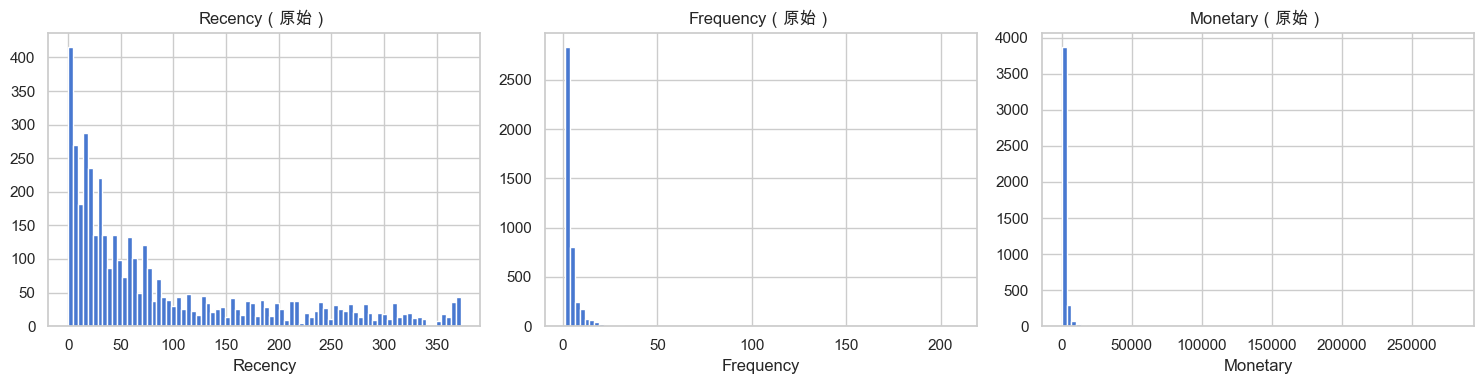

In [15]:
# ========== RFM 原始分布观察（右偏明显 → 需要变换） ==========
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 一行三列子图
for ax, col in zip(axes, rfm.columns):  # rfm.columns 就是 [Recency, Frequency, Monetary]
    ax.hist(rfm[col], bins=80)          # 画该列的直方图
    ax.set_title(f"{col}（原始）")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

## 6. 特征变换（log1p + 标准化）

RFM 三特征严重右偏，先 `log1p` 压缩动态范围，再 `StandardScaler` 统一量纲（聚类对尺度敏感）。

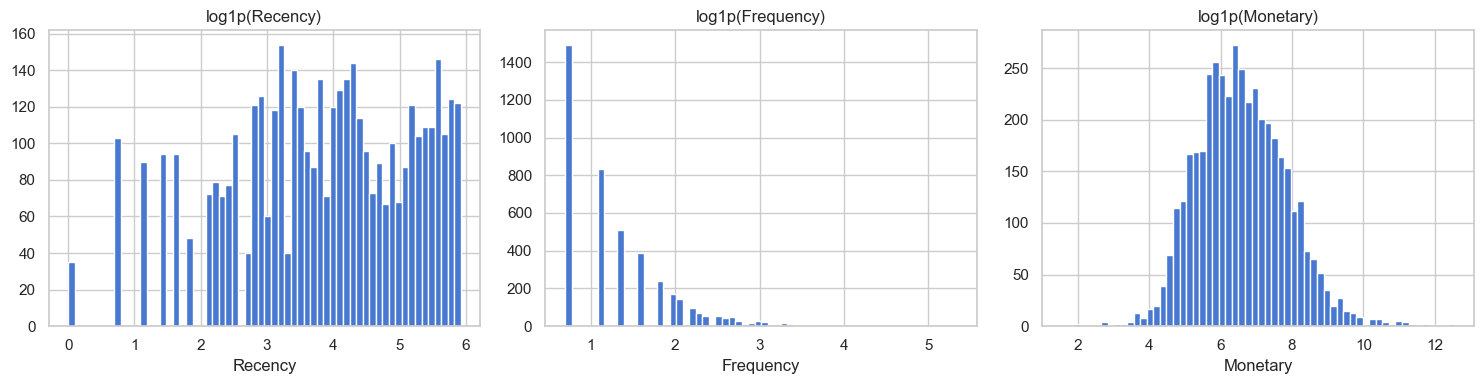

X_scaled shape: (4338, 3)


In [16]:
# ========== 第 6 节：特征变换 log1p + 标准化 ==========
rfm_log = np.log1p(rfm)   # 第一步 log1p：压缩右偏长尾（ln(1+x)，逐元素变换）
scaler = StandardScaler() # 创建标准化器实例（此刻还没做任何计算）
# 第二步标准化：fit_transform = 先 fit（学习每列的均值/标准差）再 transform（统一为「均值0、方差1」）
X_scaled = scaler.fit_transform(rfm_log)  # 返回 numpy 数组，即后续聚类用的特征矩阵 X

# 变换后分布
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, rfm.columns):
    ax.hist(rfm_log[col], bins=60)   # 画 log1p 后（尚未标准化）的分布
    ax.set_title(f"log1p({col})")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

print("X_scaled shape:", X_scaled.shape)  # 形状 = (客户数, 特征数)，即 4,338 行 × 3 列

## 7. K-means 聚类

### 7.1 选择 K：肘部法（inertia）+ 轮廓系数

⚙️ 可调整 `K_RANGE`。

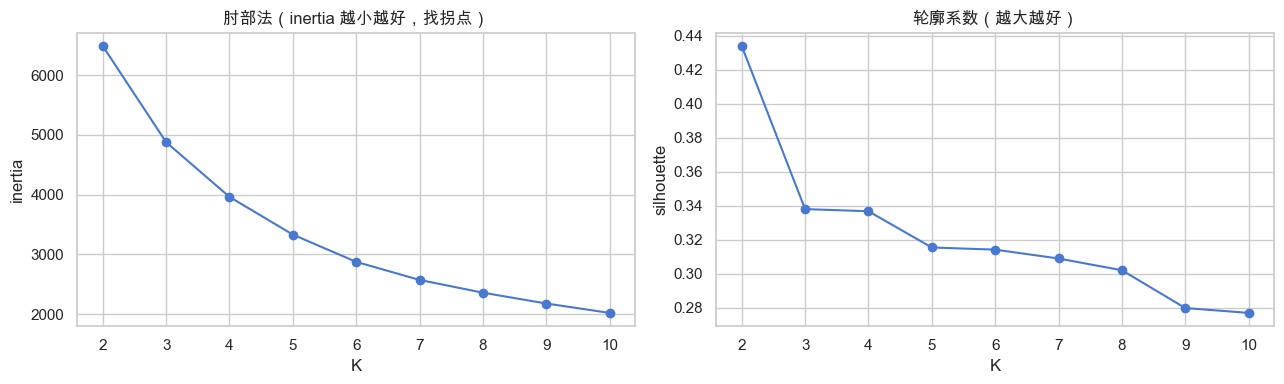

K=2: inertia=6,488  silhouette=0.4340
K=3: inertia=4,879  silhouette=0.3381
K=4: inertia=3,963  silhouette=0.3368
K=5: inertia=3,332  silhouette=0.3155
K=6: inertia=2,875  silhouette=0.3143
K=7: inertia=2,573  silhouette=0.3090
K=8: inertia=2,360  silhouette=0.3021
K=9: inertia=2,178  silhouette=0.2799
K=10: inertia=2,021  silhouette=0.2770


In [17]:
# ========== 第 7 节：选 K（K-means 的簇数） ==========
K_RANGE = range(2, 11)   # 尝试 K=2,3,...,10（range 含头不含尾）
inertias, sils = [], []  # 两个空列表：分别存每个 K 的 inertia 与 silhouette
for k in K_RANGE:        # 对每个候选 K 训练一次 K-means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)  # random_state 固定随机种子保证可复现；n_init 重复 10 次取最优
    km.fit(X_scaled)     # 训练（fit）：让模型自己学习怎么分组
    inertias.append(km.inertia_)   # inertia=簇内平方和（越小越紧凑）；append 追加到列表尾部
    sils.append(silhouette_score(X_scaled, km.labels_))  # 轮廓系数（越大越好）；labels_=每个样本被分的簇号

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(K_RANGE), inertias, marker="o")  # 左图：inertia 随 K 变化的折线
axes[0].set_title("肘部法（inertia 越小越好，找拐点）")
axes[0].set_xlabel("K"); axes[0].set_ylabel("inertia")  # 分号 = 一行写两句话
axes[1].plot(list(K_RANGE), sils, marker="o")    # 右图：轮廓系数随 K 变化
axes[1].set_title("轮廓系数（越大越好）")
axes[1].set_xlabel("K"); axes[1].set_ylabel("silhouette")
plt.tight_layout()
plt.show()

# zip(...)：把多个序列按位置一一对应；这里循环同时取到 K、inertia、silhouette
for k, i, s in zip(K_RANGE, inertias, sils):
    print(f"K={k}: inertia={i:,.0f}  silhouette={s:.4f}")  # :.4f = 保留 4 位小数

### 7.2 拟合 K-means

⚙️ 根据 7.1 结果把 `K_BEST` 改成合适的值（如 4）。

In [18]:
# ========== 用选定 K 训练最终 K-means ==========
K_BEST = 4  # ⚙️ 依据上图调整（肘部 + 轮廓系数综合选 4）
km = KMeans(n_clusters=K_BEST, random_state=42, n_init=10)
km.fit(X_scaled)

rfm["Cluster_KM"] = km.labels_  # 把每个客户的簇号（0~3）存成新列
print("簇大小:", rfm["Cluster_KM"].value_counts().sort_index().to_dict())
# value_counts() 统计每簇人数；sort_index() 按簇号 0,1,2,3 排序；to_dict() 转成字典方便打印

簇大小: {0: 699, 1: 1635, 2: 826, 3: 1178}


## 8. DBSCAN 聚类

### 8.1 选 eps：K 近邻距离图

⚙️ `MIN_PTS`（min_samples）通常取 ≥ 特征维度+1（这里 ≥4），观察 KNN 距离曲线的「拐点」即为合理 eps。

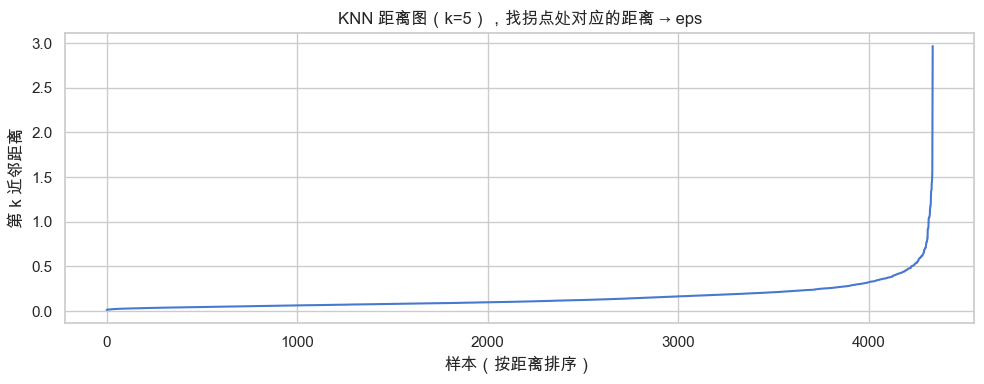

In [19]:
# ========== 给 DBSCAN 选参数 eps：KNN 距离图 ==========
MIN_PTS = 5  # ⚙️ 最小样本数（DBSCAN 密度阈值，一般取 2×特征数或按经验）
nn = NearestNeighbors(n_neighbors=MIN_PTS)  # 找每个点的最近 MIN_PTS 个邻居
nn.fit(X_scaled)
dists, _ = nn.kneighbors(X_scaled)  # 返回 (距离, 邻居索引)；_ 表示用不到的索引部分
kdist = np.sort(dists[:, -1])       # 每行取「第 k 近」的距离（最后一位=最远的邻居），再整体升序排序

plt.figure(figsize=(10, 4))
plt.plot(kdist)  # 画排序后的距离曲线
plt.title(f"KNN 距离图（k={MIN_PTS}），找拐点处对应的距离 → eps")
plt.xlabel("样本（按距离排序）")
plt.ylabel("第 k 近邻距离")
plt.tight_layout()
plt.show()

### 8.2 拟合 DBSCAN

⚙️ 根据 8.1 拐点设 `EPS`。`min_samples=5` 起步。

In [20]:
# ========== 训练 DBSCAN ==========
EPS = 0.6  # ⚙️ 依据拐点调整（KNN 距离图拐点处的 y 值）
dbs = DBSCAN(eps=EPS, min_samples=MIN_PTS)  # eps=邻域半径；min_samples=半径内最少点数才算「核心点」
dbs.fit(X_scaled)

rfm["Cluster_DB"] = dbs.labels_   # -1 = 噪声点（不属于任何簇的离群样本）
n_noise = (dbs.labels_ == -1).sum()   # 统计噪声点个数（True 计为 1）
print(f"簇数: {len(set(dbs.labels_)) - (1 if n_noise else 0)} | 噪声点: {n_noise:,} ({n_noise/len(rfm):.1%})")
# set(labels) 去重后数个数；若含 -1 则减 1；:.1% = 显示成百分比（保留 1 位小数）
print("簇大小:", rfm["Cluster_DB"].value_counts().sort_index().to_dict())

簇数: 1 | 噪声点: 43 (1.0%)
簇大小: {-1: 43, 0: 4295}


## 9. 对比评估

### 9.1 内部指标

无真实标签，用**内部指标**（轮廓系数 / DBI / CH）横向对比两种算法。DBI 越小越好，其余越大越好。

In [21]:
# ========== 定义评估函数，统一比较两种算法 ==========
# def 定义函数；参数 X=特征矩阵, labels=每个样本的簇号, name=算法名
def metrics(X, labels, name):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)  # 簇数（含 -1 时把噪声那一类减掉）
    return {
        "算法": name,
        "簇数": n_clusters,
        "噪声点": int((labels == -1).sum()),
        "轮廓系数": round(silhouette_score(X, labels), 4),       # 越大越好（范围 -1~1）
        "DBI": round(davies_bouldin_score(X, labels), 4),       # 戴维森-布尔丁指数，越小越好
        "CH": round(calinski_harabasz_score(X, labels), 2),    # 卡林斯基-哈拉巴斯指数，越大越好
    }

rows = [   # 用同一个评估函数分别算 K-means 和 DBSCAN 的分数
    metrics(X_scaled, rfm["Cluster_KM"].values, "K-means"),   # .values 把 pandas 列转成 numpy 数组
    metrics(X_scaled, rfm["Cluster_DB"].values, "DBSCAN"),
]
pd.DataFrame(rows).set_index("算法")   # 列表 → 表格，并把「算法」列设为行索引

,簇数,噪声点,轮廓系数,DBI,CH
算法,,,,,
K-means,4,0,0.34,1.01,"3,299.86"
DBSCAN,1,43,0.55,1.10,220.61


### 9.2 可视化：PCA 与 t-SNE 双视角

PCA 看全局方差结构，t-SNE 看局部近邻（perplexity 建议 30 附近，结果不稳定属正常）。

In [22]:
# ========== 降维到 2D，用于可视化 ==========
pca = PCA(n_components=2, random_state=42)  # 降到 2 维（只保留前两个主成分）
X_pca = pca.fit_transform(X_scaled)          # fit 学习投影方向，transform 把数据投影过去
print("PCA 累计解释方差:", pca.explained_variance_ratio_.sum().round(4))  # 2 个主成分保留了多少信息量
# explained_variance_ratio_ = 每个主成分解释的方差占比（信息量），PC1/PC2 分别打印
print("PC1 解释方差:", pca.explained_variance_ratio_[0].round(4),  # 第一主成分（横向信息量，本项目 75.2% = 最重要的方向）
      "| PC2 解释方差:", pca.explained_variance_ratio_[1].round(4))  # 第二主成分（纵向信息量，18.7%）

# t-SNE：另一种降维（更擅长把相近的样本在图上聚在一起，适合观察簇形状）
# perplexity=30 邻域大小；init="pca" 用 PCA 结果初始化；learning_rate="auto" 自动学习率
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42, learning_rate="auto")
X_tsne = tsne.fit_transform(X_scaled)

PCA 累计解释方差: 0.9387
PC1 解释方差: 0.7517 | PC2 解释方差: 0.187


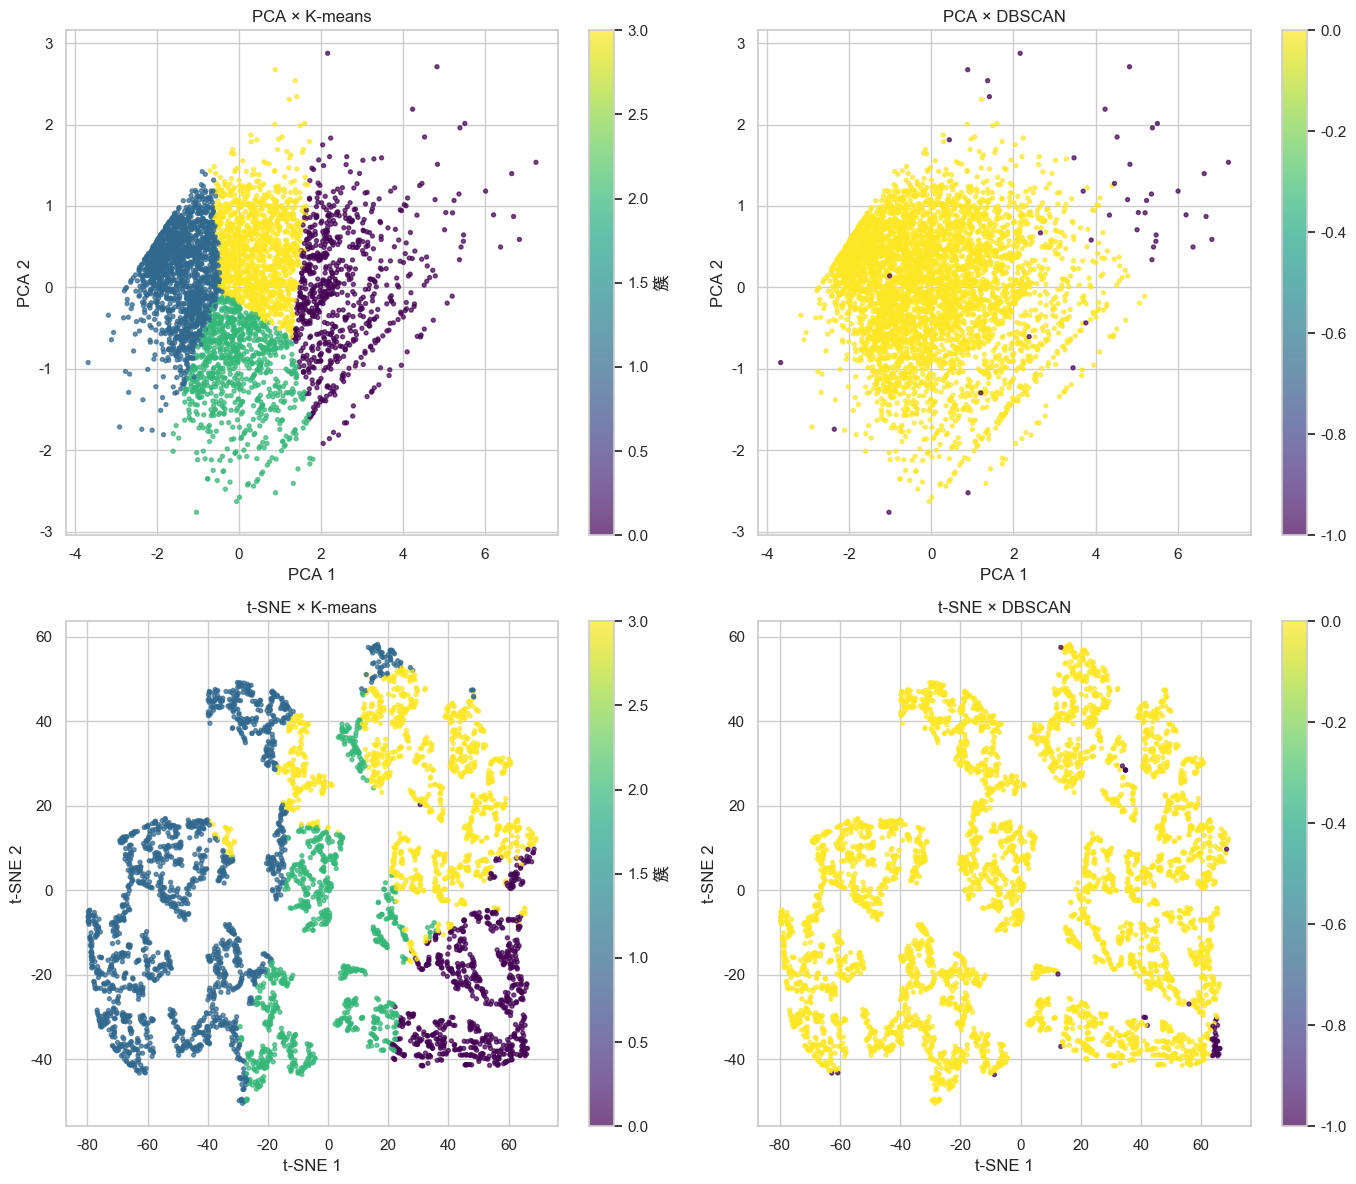

In [23]:
# ========== 画 2×2 大图：2 种降维 × 2 种聚类 ==========
fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # 2 行 2 列子图
views = [("PCA", X_pca), ("t-SNE", X_tsne)]       # 行方向：两种降维视图
algs = [("K-means", "Cluster_KM", True), ("DBSCAN", "Cluster_DB", False)]  # 列方向：两种算法（第 3 项=是否用整数直接上色）

# enumerate 同时拿到序号 r（0/1）和内容 (降维名, 坐标数组)
for r, (vname, Xv) in enumerate(views):
    # 内层循环处理每一列；c=列序号，aname=算法名，col=簇号列名，use_cmap=是否直接用整数作色
    for c, (aname, col, use_cmap) in enumerate(algs):
        ax = axes[r][c]   # 取第 r 行第 c 列的子图
        if use_cmap:
            # scatter 散点图：Xv[:,0]=横坐标，Xv[:,1]=纵坐标，c=按簇号上色
            sc = ax.scatter(Xv[:, 0], Xv[:, 1], c=rfm[col], cmap="viridis", s=8, alpha=0.7)
            fig.colorbar(sc, ax=ax, label="簇")   # 右侧颜色条，标注簇号
        else:
            # DBSCAN 的噪声点是 -1，先转成 float 才能与正常簇共用同一张颜色图
            colors = np.where(rfm[col] == -1, -1.0, rfm[col].astype(float))  # np.where：条件成立取前者，否则取后者
            sc = ax.scatter(Xv[:, 0], Xv[:, 1], c=colors, cmap="viridis", s=8, alpha=0.7)
            fig.colorbar(sc, ax=ax)
        ax.set_title(f"{vname} × {aname}")
        ax.set_xlabel(f"{vname} 1"); ax.set_ylabel(f"{vname} 2")
plt.tight_layout()
plt.show()

### 9.2b 结果观察与推论（新手读图指南）

**先明确图的结构**：上行 = PCA（看全局方差），下行 = t-SNE（看局部近邻）；左列 = KMeans，右列 = DBSCAN。颜色 = 聚类标签，同一颜色在左右两列之间**没有对应关系**（KMeans 的簇 0~3 与 DBSCAN 的簇 0 / -1 含义不同）。

**颜色怎么对应**：两列都共用 `viridis` 色带（深紫 → 蓝紫 → 黄绿 → 亮黄），但同一颜色在左右两列**含义不同**：
- **KMeans 图**：簇号 0/1/2/3 均匀映射 → 簇 0 = 深紫、簇 1 = 蓝紫、簇 2 = 黄绿、簇 3 = 亮黄（colorbar 标注「簇」）；
- **DBSCAN 图**：只有 -1（噪声）和 0（主体簇）→ 噪声 = 深紫、主体 = 亮黄（colorbar 刻度 -1 / 0）；
- ⚠️ **最容易看混的地方**：KMeans 图的**深紫 = 高价值簇 0**，DBSCAN 图的**深紫 = 噪声点**，同色不同义，读图时先看所在列。

#### ① PCA 行（上行）：PCA × KMeans / PCA × DBSCAN

- **可信度**：前 2 个主成分累计解释了 **93.87%** 的方差（PC1=75.2%，PC2=18.7%），说明用 2 维展示几乎没有丢信息，这张图基本反映了全貌。
- **KMeans 图**：4 个簇（深紫→亮黄）大致沿一条斜带依次排开，而不是 4 个独立圆团——说明客户价值是**连续渐变**的，簇与簇之间边界模糊。这正是轮廓系数只有 0.337（中等偏弱）的直观体现。
- **DBSCAN 图**：几乎看不到多簇结构（亮黄主体一片 + 43 个深紫噪声点）。因为 DBSCAN 按「密度分界」找簇，而 RFM 数据密度均匀渐变、没有天然空隙，所以它在这里失效。

#### ② t-SNE 行（下行）——新手最困惑的部分

先记住 3 条铁律，否则很容易过度解读：

1. **t-SNE 的坐标数值和点间距离没有绝对意义**——横纵轴单位是任意的，只有「谁和谁聚在一起 / 谁和谁分开」有含义；
2. **每次运行图都会变**（t-SNE 有随机性），不要记住具体位置，只看每次都会稳定出现的相对结构；
3. t-SNE 会**夸大局部聚集**（把相近的点拉得更近），所以「图里分得开」≠「聚类真的可分」，必须结合轮廓系数 0.337 一起判断。

在图里能稳定观察到的结构（已用数据验证）：

- **高价值簇 0（699 人，深紫色）聚得最紧**：在图中占据一角且内部紧凑——说明高价值客户彼此高度相似、天然抱团，是特征鲜明的「精英群体」；
- **沉睡簇 1（1,635 人，蓝紫色）铺得最开**：散布最大——说明「沉睡客户」内部分化严重，他们唯一的共同点只是「最近没再来」，其他方面什么样的人都有；
- **簇 2（黄绿色）、簇 3（亮黄色）夹在中间，与两端有重叠**：再次印证「边界模糊、连续渐变」；
- **DBSCAN 的 43 个噪声点（右下图深紫色）集中在高价值角落**：这些「被当作噪声」的点其实是行为极端的大客户（离群于主体密度），不是垃圾数据，值得单独关注。

#### ③ 综合推论（对业务）

1. 两个极端是「清晰」的（高价值精英 / 沉睡人群），中间是连续过渡带 → 营销上适合先抓两头：对簇 0 做会员权益与交叉销售，对簇 1 谨慎评估挽回成本；
2. 簇 1 虽大（占 38%）但内部分化，不能「一刀切」挽回，需要再细分；
3. DBSCAN 的结论提示：极端高价值客户是「稀少但独特」的群体，密度聚类会把它们识别为孤立点，人工关注这些客户可能有额外价值。

### 9.3 簇画像（业务解读）

看每个簇的 RFM 中位数/均值，给簇「贴标签」。

In [24]:
# ========== K-means 簇画像 ==========
# groupby 按簇分组，只取 RFM 三列，.median() 求每组中位数（比均值更抗离群点）
km_profile = rfm.groupby("Cluster_KM")[["Recency", "Frequency", "Monetary"]].median()
km_profile["客户数"] = rfm.groupby("Cluster_KM").size()  # 新增列：每簇有多少客户
km_profile.round(1)  # 所有数字保留 1 位小数并显示（Jupyter 自动显示 cell 最后一个表达式）

,Recency,Frequency,Monetary,客户数
Cluster_KM,,,,
0,8.00,10.00,"3,750.40",699
1,173.00,1.00,296.60,1635
2,16.00,2.00,480.10,826
3,53.50,4.00,"1,351.80",1178


In [25]:
# ========== DBSCAN 簇画像（排除噪声 -1） ==========
# 先过滤掉噪声行（!= -1），再按簇分组求中位数
db_profile = rfm[rfm["Cluster_DB"] != -1].groupby("Cluster_DB")[["Recency", "Frequency", "Monetary"]].median()
db_profile["客户数"] = rfm[rfm["Cluster_DB"] != -1].groupby("Cluster_DB").size()
db_profile.round(1)

,Recency,Frequency,Monetary,客户数
Cluster_DB,,,,
0,51.00,2.00,659.40,4295


## 10. 结论与业务建议

（基于 9.3 簇画像与 11.2 簇中心读图填写，RFM 取中位数）

| 簇 | 画像（RFM 中位数） | 特征 | 价值定位（客户数 / 占比） | 营销建议 |
|----|------|---------|---------|---------|
| 0 | R 8 天 · F 10 次 · M 3,750 元 | R 最小、F / M 最高 | **活跃高价值**（699 人，16%） | 核心客户：会员权益、交叉销售、新品首发、专属客服 |
| 1 | R 173 天 · F 1 次 · M 297 元 | R 最大、F / M 最低 | **沉睡低价值**（1,635 人，38%） | 流失预警 + 唤醒活动（价值低，投入需谨慎） |
| 2 | R 16 天 · F 2 次 · M 480 元 | R 低、F / M 低 | **近期低频 · 新客为主**（826 人，19%） | 促复购：首购后 30 天内二次触达、组合优惠 |
| 3 | R 54 天 · F 4 次 · M 1,352 元 | 三项居中 | **中等价值**（1,178 人，27%） | 提升客单价、会员升级、推荐高价值品类 |

> 簇 1（沉睡低价值）占比最大（38%），是流失预警与召回的重点对象；簇 0（活跃高价值）仅 16%，却是利润核心，应优先维护。簇与簇之间是**连续渐变**而非断裂（轮廓系数 0.337，见 11.1），营销上可做分层而非一刀切。

> **指标说明**：本项目无真实标签，ARI/NMI 外部验证不适用。实测 K-means 与 DBSCAN 的标签一致性（`adjusted_rand_score` / `normalized_mutual_info_score`，噪声单独处理后计算）均为 0——DBSCAN 只识别出 1 个簇时，一致性指标在定义上无意义，故不再单独对比（详见 11.1 表格）。

In [26]:
# ========== 导出客户分群结果（供后续报告使用） ==========
# to_csv 把 rfm 表保存为 CSV；index_label 把行索引列命名为 CustomerID
rfm.to_csv("../data/customer_rfm_clustered.csv", index_label="CustomerID")
print("已导出 -> ../data/customer_rfm_clustered.csv")

已导出 -> ../data/customer_rfm_clustered.csv


## 11. 深化分析：可视化与结果解读

> 本节对第 9~10 节的结果做**扩展可视化**与**深度解读**。

### 11.0 先建立直觉：监督学习 vs 聚类（无监督）

很多评估手段来自**监督学习**——数据带着「标准答案」（标签），模型学的是「输入 → 答案」的映射，所以能检查「预测得准不准」（残差 / 拟合优度），也能看「哪些输入最有用」（特征重要性）。

而**聚类是无监督学习**——数据没有标签，模型自己把相似的样本归堆，没有「正确答案」可比，所以上面那些手段**没有直接对应物**，只能找「等价物」从侧面验证分群质量。下面把 5 个常见监督学习概念翻译成聚类的检查方式（也是本节 11.1~11.8 的组织逻辑）：

| 监督学习概念（一句话解释） | 聚类等价物 | 本节 | 具体到两种算法 |
|---|---|---|---|
| **特征重要性**：哪些输入变量对预测贡献最大 | **特征区分度**：哪些 RFM 维度最能把簇分开 | 11.3 | 与算法无关，两种算法都能算 η²；但 DBSCAN 只有 1 个簇时无法算「簇间差异」 |
| **残差 / 拟合优度**：预测与真实差多少、整体拟合得多好 | **簇中心热力图 + 簇间箱线图**：簇的「代表值」和簇内离散度 | 11.2 + 11.4 | K-means 有簇中心（质心）→ 可画热力图；DBSCAN 没有质心，只能靠箱线图看分布 |
| **学习曲线**：样本量增加时性能是否收敛 | **聚类稳定性**：抽样量变化时，簇结构与标签是否稳定 | 11.5 | K-means 看轮廓系数 + ARI 随样本量收敛；DBSCAN 只有 1 簇时 ARI 无意义 |
| **模型行为诊断**：检查模型在什么场景下失灵 | **调参诊断**：扫参数看模型行为如何变化 | 11.6 | DBSCAN 专属（eps 扫描解释为何塌缩成 1 簇）；K-means 不需要 |
| **业务可解释性**：结果能否翻译成业务语言 | **业务空间散点**：把簇放回原始业务坐标 | 11.7 | K-means 簇 → 商业象限；DBSCAN 噪声点 = 行为极端的大客户 |

**本节地图**（为什么按这个顺序看）：
- **11.1** 先总览：两个算法谁行谁不行（质量指标对比）；
- **11.2 → 11.4** 再看结构：K-means 学到了什么（簇中心）→ 哪些特征在切分（区分度）→ 簇内分布长什么样（箱线图）；
- **11.5 → 11.6** 诊断稳健性：结果可复现吗（稳定性）→ DBSCAN 为什么失败（eps 扫描）；
- **11.7** 落到业务：把簇翻译成商业象限；
- **11.8** 收尾：局限与改进方向。


### 11.1 结果质量评估

| 指标 | K-means (K=4) | DBSCAN (eps=0.6) | 说明 |
|---|---|---|---|
| 簇数 | 4 | 1 + 43 噪声 | DBSCAN 实际只识别出 1 个簇 |
| 轮廓系数 | 0.337 | 0.552 | DBSCAN 的 0.552 是「几乎 1 个簇」的**假象**，无区分意义 |
| DBI | 1.01 | 1.10 | 只有 1 个簇时 DBI 定义退化，不可比 |
| CH | 3,299.86 | 220.61 | CH 需要多簇才有意义，220 说明 DBSCAN 未分裂出结构 |
| ARI / NMI | — | 0.0 / 0.0 | 两算法标签零一致：DBSCAN 无有效划分 |

**结论**：
- **K-means 可用，但属「中等偏弱」**：轮廓系数 0.337（>0.5 才算结构清晰）说明 RFM 空间里簇与簇**边界模糊、呈连续层级分布**——从「沉睡」到「高频高价值」是渐变而非断裂。
- **DBSCAN 调参/选型失败**：eps=0.6 把 99% 的点连成 1 个簇，根源见 11.6。
- 因此后续解读以 **K-means (K=4) 为主**，DBSCAN 仅作对照并说明为何不适用。

### 11.2 簇中心热力图（模型「学到了什么」）

每个格子是 K-means 在标准化空间的簇中心：**0 = 全体均值，红 = 偏高，蓝 = 偏低**。

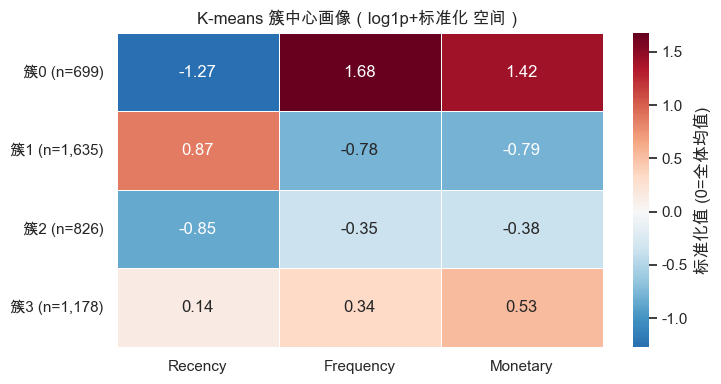

In [27]:
# ========== 簇中心画像（热力图）：一眼看出每个簇的 RFM 高低特征 ==========
# km.cluster_centers_：K-means 训练后每个簇的中心点（在标准化空间里的坐标），形状 (K, 3)
center_df = pd.DataFrame(km.cluster_centers_, columns=["Recency", "Frequency", "Monetary"])
center_df.index = [f"簇{i}" for i in range(K_BEST)]  # 行标签改为 簇0, 簇1, ...
# 列表推导式 [f"簇{i}" for i in range(K_BEST)]：一行生成 K 个「簇i」字符串
center_df["客户数"] = rfm["Cluster_KM"].value_counts().sort_index().values  # 追加每簇人数

fig, ax = plt.subplots(figsize=(7.5, 4))
# 热力图：中心值越高越红、越低越蓝；center=0 让 0（全体均值）正好处于红蓝分界
sns.heatmap(center_df.iloc[:, :3], annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            yticklabels=[f"簇{i} (n={n:,})" for i, n in enumerate(center_df["客户数"])],  # 行标签带上人数
            linewidths=0.5, ax=ax, cbar_kws={"label": "标准化值 (0=全体均值)"})
ax.set_title("K-means 簇中心画像（log1p+标准化 空间）")
plt.tight_layout()
plt.show()

**读图**：
- **簇0**：Recency 最低（最活跃）、Frequency/Monetary 最高 → **活跃高价值**，699 人（16%）。
- **簇1**：三项全蓝且 Recency 最高 → **沉睡低价值**，1,635 人（38%，占比最大）。
- **簇2**：Recency 偏低但 F/M 也低 → **近期低频（新客为主）**，826 人（19%）。
- **簇3**：三项居中 → **中等价值**，1,178 人（27%）。
> 注意：簇编号是算法输出顺序（簇0 恰好最活跃），不代表重要性排序。

### 11.3 特征区分度（聚类版「特征重要性」）

对每个 RFM 特征计算 **η² = 组间方差 / 总方差**：该特征被「簇」解释的比例（0~1），越大说明它越能区分簇。在 log1p 空间计算，与聚类空间一致。

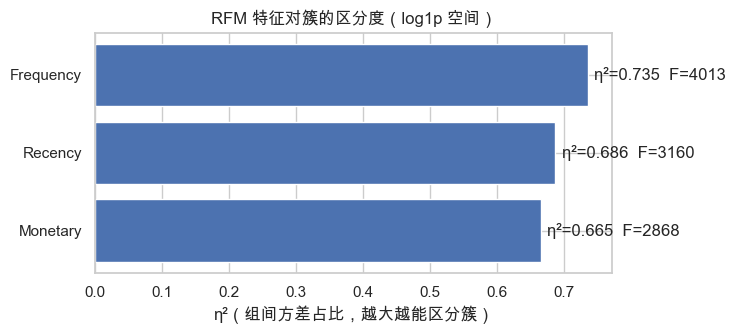

,特征,η²,F值,p值
0,Frequency,0.74,"4,013.32",0.00
1,Recency,0.69,"3,159.54",0.00
2,Monetary,0.67,"2,867.60",0.00


In [28]:
# ========== 11.3 特征区分度：η²（组间方差占比）+ 单因素方差分析 ==========
from scipy.stats import f_oneway  # 单因素方差分析：检验多组均值是否显著不同

labels = rfm["Cluster_KM"].values  # 每个客户的簇号（0~3），转成 numpy 数组
imp_rows = []  # 存每个特征的统计结果（后面拼成表格）
for feat in ["Recency", "Frequency", "Monetary"]:
    v = np.log1p(rfm[feat].values)  # 同样先 log1p（与聚类空间保持一致）
    # η²（eta 平方）= 组间方差 / 总方差：越接近 1，说明该特征对簇的区分度越高
    ss_tot = ((v - v.mean()) ** 2).sum()   # 总平方和：每个值离全体均值的差距平方再求和
    # 组间平方和：每簇均值与全体均值差距的平方 × 该簇样本数，再累加（列表推导式 + sum）
    ss_bet = sum(len(v[labels == c]) * (v[labels == c].mean() - v.mean()) ** 2 for c in range(K_BEST))
    F, p = f_oneway(*[v[labels == c] for c in range(K_BEST)])  # * 把列表拆成多个参数传入；p<0.05 说明簇间差异显著
    imp_rows.append({"特征": feat, "η²": ss_bet / ss_tot, "F值": F, "p值": p})
# sort_values 按 η² 降序排序；reset_index(drop=True) 重置行号从 0 开始
imp_df = pd.DataFrame(imp_rows).sort_values("η²", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(imp_df["特征"], imp_df["η²"], color="#4C72B0")  # barh 横向柱状图
ax.invert_yaxis()  # 让 η² 最大的特征排在最上面
ax.set_xlabel("η²（组间方差占比，越大越能区分簇）")
ax.set_title("RFM 特征对簇的区分度（log1p 空间）")
for i, r in imp_df.iterrows():  # iterrows：逐行取出（i=行号，r=该行内容）
    ax.text(r["η²"] + 0.01, i, f"η²={r['η²']:.3f}  F={r['F值']:.0f}", va="center")  # 在柱子末端标注数值
plt.tight_layout()
plt.show()

imp_df.round(4)  # 表格数字保留 4 位小数显示

**读图**：η² 越大，该特征在簇间差异越明显，是「切分客户」的主要驱动。
- 实测：**Frequency η²=0.735 > Recency 0.686 > Monetary 0.665**，三者都有强区分力（η²>0.6），说明 RFM 三个维度对分群都有贡献，没有废特征。
- Frequency 略胜一筹：K-means 实际最依赖「买了几次」来切分人群；Monetary 相对最弱（受极端值影响，见 11.8）。
- F 值数千、p≈0：簇间差异统计显著。但注意——**p 值在这里不能用来比较特征**！三个特征 p 都是 0.00（实际 <1e-300），是因为样本量高达 4,338，只要簇间均值有一丁点差异，p 值就必然趋近 0（大样本下「统计显著」很容易达到）。
- p 值回答「差异是否存在」，η² 回答「差异有多大」；比较特征重要性**只看 η²**（效应量，不受样本量影响）。排序：Frequency 0.735 > Recency 0.686 > Monetary 0.665。

### 11.4 簇间分布对比（箱线图 + 中位数）

在 log1p 空间看每个簇内的完整分布，避免原始尺度极端值撑爆坐标轴。三个子图分别对应 Recency / Frequency / Monetary，每个子图里有 4 个箱（簇 0~3）。

**箱线图（盒须图）怎么读**：每个「箱」代表一个簇在某个 RFM 维度上的分布——

- **箱体**：下边 = Q1（25 分位）、上边 = Q3（75 分位），箱体高度 = IQR（四分位距），**箱内包含了该簇约 50% 的客户**；
- **箱中横线**：**中位数（Q2）**——标题里的「+ 中位数」即指此线，代表该簇的「典型水平」，也是簇间横向对比的主要依据；
- **须（whisker）**：从箱体上下边伸出的线段（末端带小横线），它的**端点（最高点/最低点）**不是数据的最大值/最小值，而是 **1.5×IQR 界限以内**最远的数据点，反映「正常波动范围」的边界；
- **圆点（fliers/离群点）**：超出 1.5×IQR 界限的数据点，单独画成圆点，说明簇内存在「极端个体」。

**「有了须端点，为什么还有离群点？」——用真实数据一次说清**（簇 0 的 Monetary，log1p 值，n=699）：

- 分位数：Q1=7.78、Q3=8.77、IQR=1.00 → **上界限 = Q3 + 1.5×IQR = 10.26**（这条界线图上是虚线，不显示）；
- 数据真实最大值 = **12.54**，它比上界限大 2.28，**超出了「正常范围」→ 只能画成圆点**，进不了须；
- 上须端点 = 10.25：它是**没超过界限**的数据里最大的那个；上须端点下方 10.27 的客户只比界限大 0.01，也被判为离群点（上方共 30 个圆点）；

```
        o            ← 离群点(圆点)：超出上界限 Q3+1.5×IQR 的客户
        o              （簇 0 中 log1p(Monetary) > 10.26 的 30 个客户）
    ────────          ← 上须端点(小横线)：界限内最远的点 = 10.25
    │      │
    ├──────┤          ← Q3 = 8.77（箱上边）
    │ 箱体  │
    ├──────┤          ← Q2 = 中位数
    │      │
    ├──────┤          ← Q1 = 7.78（箱下边）
    │      │
    ────────          ← 下须端点 = 6.69（界限内最远的点）
        o            ← 离群点(圆点)
```

一句话总结：**须端点负责「正常范围」，圆点负责「超出正常范围」**。须的最高点被 1.5×IQR 界限「卡住」，数据里真正最大/最小的极端客户永远进不了须，只能画在须外面的圆点位置。

> **注意**：坐标为 log1p 后的值，三个子图之间**不可直接比大小**（量纲不同，见 3.4 的 log1p 说明）；但**同一特征内簇与簇之间可直接对比**——log1p 是单调递增变换，簇的相对高低在 log 空间与原始空间一致。

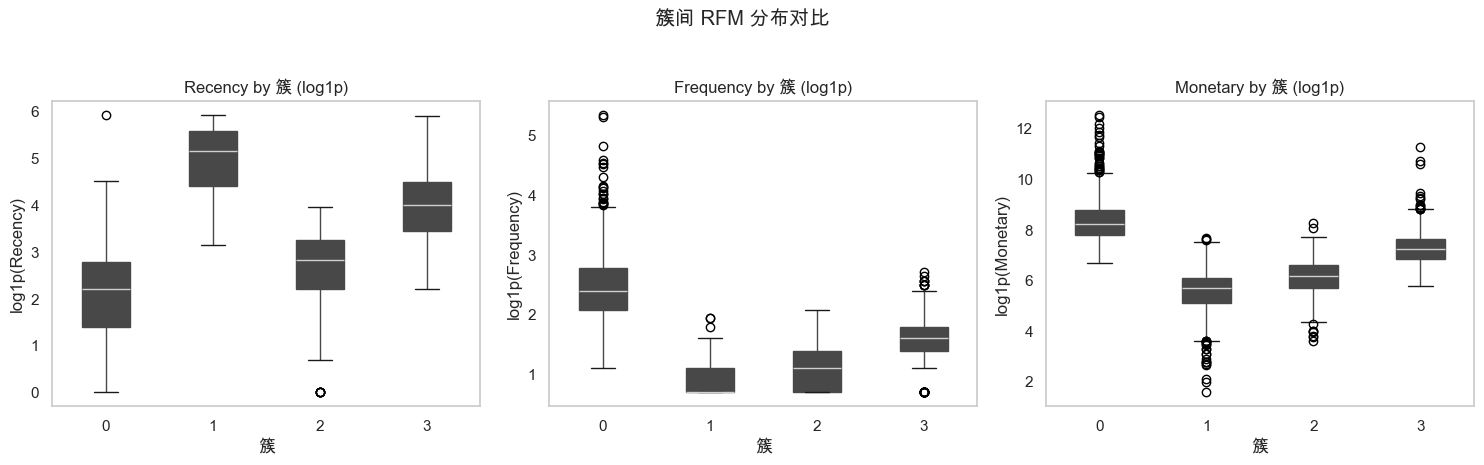

In [29]:
# ========== 11.4 簇间 RFM 分布对比（箱线图） ==========
# 箱体位置 = 簇中心，箱体宽度 = 簇内异质性（读图方法见 11.4 的 markdown 说明）
rfm_log_view = np.log1p(rfm[["Recency", "Frequency", "Monetary"]]).copy()  # 拷贝一份 log1p 后的表（不改动原表）
rfm_log_view["Cluster_KM"] = labels  # 加上簇号列，供分组使用

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))  # 三个子图：Recency / Frequency / Monetary
for ax, feat in zip(axes, ["Recency", "Frequency", "Monetary"]):
    # boxplot 画箱线图：column=要画的列，by="Cluster_KM" 按簇分组
    # grid=False 去掉网格线；patch_artist=True 给箱体填充颜色
    rfm_log_view.boxplot(column=feat, by="Cluster_KM", ax=ax, grid=False, patch_artist=True)
    ax.set_title(f"{feat} by 簇 (log1p)")
    ax.set_xlabel("簇"); ax.set_ylabel(f"log1p({feat})")
fig.suptitle("簇间 RFM 分布对比", y=1.03)  # 整张图的总标题（y=1.03 微调位置避免与子图标题重叠）
plt.tight_layout()
plt.show()

**读图（逐元素解析）**：
- **箱中位线位置 → 簇间对比**：看同一特征下 4 个箱的中位数高低，即可横向比较各簇的典型水平。如 Monetary 子图中簇 0 中位数最高、簇 1 最低；Recency 子图中簇 0 最低（最活跃）、簇 1 最高（最久没消费）——「簇 0 活跃高价值、簇 1 沉睡低价值」在分布层面再次得到验证，与 11.2 簇中心一致。
- **箱体宽度（IQR）→ 簇内异质性**：箱越高，说明簇内约 50% 客户的跨度越大（内部越不齐）。注意：**异质性要按特征分别看，不能笼统说「某个簇整体宽/窄」**。实测箱高（log1p 空间 IQR）：

  | 簇 | Recency | Frequency | Monetary |
  |----|---------|-----------|----------|
  | 0 活跃高价值 | **1.39（最高）** | 0.69（并列最高） | 1.00 |
  | 1 沉睡 | 1.18 | **0.41（最矮）** | 0.99 |
  | 2 近期低频 | 1.06 | 0.69 | 0.91 |
  | 3 中等价值 | 1.05 | 0.41 | 0.79 |

  - **Recency：簇 0 箱最高（1.39）** → 活跃客户内部「最近购买间隔」参差（有人 1 周内刚买、有人已 40+ 天），「活跃」内部其实还能细分；
  - **Frequency：簇 1 箱最矮（0.41）** → 沉睡客户几乎都只买过 1~2 次，这才是真正的高度同质；
  - **Monetary：四簇箱高接近（0.79~1.00）** → 这个特征上簇间异质性差异不大，不适合用它讲「可再分层」。
- **须与圆点 → 尾部形态**：须长说明有较多客户接近正常波动边界；圆点（离群点）说明簇内存在极端个体（如簇 0 中 log1p(Monetary) 极高的顶级客户）。箱线图只用分位数，比均值 ± 标准差更抗离群点，正适合右偏数据。
- **箱体重叠程度 → 簇边界清晰度**：重叠多 = 该维度上簇边界模糊；重叠少 = 区分清晰。三个特征上簇间均有明显错位（与 11.3 高 η² 互证），但边缘仍有交叉 → 簇边界「清晰中有重叠」，与轮廓系数 0.337（中等偏弱）相互呼应。

### 11.5 聚类稳定性（聚类版「学习曲线」）

从全量数据中**随机抽样不同样本量重复聚类**：看（a）轮廓系数是否收敛；（b）分群结果与全量标签的 **ARI 一致性**是否趋近 1。这回答「结果可复现吗、样本够不够」。

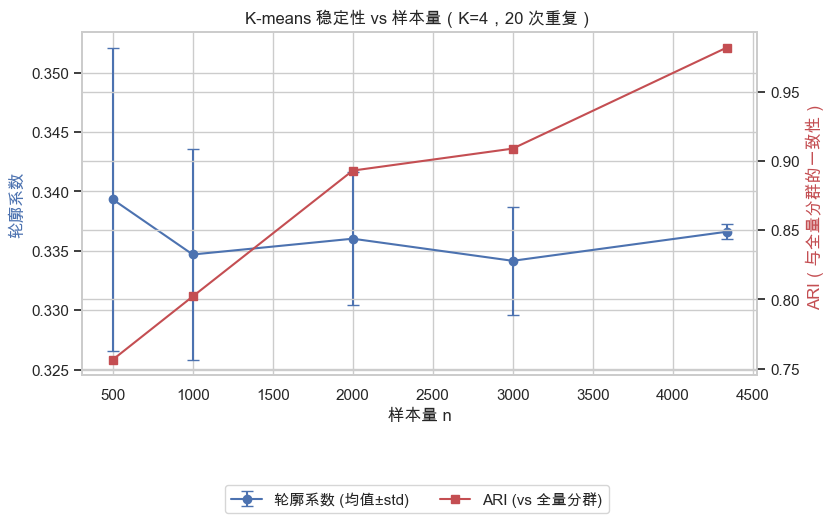

In [30]:
# ========== 附录：K-means 稳定性测试（样本量对结果的影响） ==========
from sklearn.metrics import adjusted_rand_score  # ARI：衡量两次聚类分群结果的一致程度（0=随机、1=完全一致）
rng = np.random.default_rng(42)  # 创建随机数生成器（42=种子，保证每次结果一致、可复现）
sizes = [500, 1000, 2000, 3000, 4338]  # 尝试的样本量（从小到大，4338=全量）
reps = 20  # 每个样本量重复 20 次再取平均，避免偶然性
ref_labels = km.labels_  # 全量数据的分簇结果，作为「标准答案」用来比对
sil_mean, sil_std, ari_means = [], [], []  # 存每档样本量的均值/标准差/ARI

for n in sizes:  # 遍历每种样本量
    sil_tmp, ari_tmp = [], []  # 暂存当前样本量的 20 次重复结果
    for _ in range(reps):  # 重复 20 次
        idx = rng.choice(len(X_scaled), size=n, replace=False)  # 不放回抽样 n 个样本的下标
        kk = KMeans(n_clusters=K_BEST, random_state=42, n_init=10).fit(X_scaled[idx])  # 只在抽中的样本上聚类
        sil_tmp.append(silhouette_score(X_scaled[idx], kk.labels_))  # 算抽样数据的轮廓系数
        ari_tmp.append(adjusted_rand_score(ref_labels[idx], kk.labels_))  # 抽样分群 vs 全量分群的一致性
    sil_mean.append(np.mean(sil_tmp)); sil_std.append(np.std(sil_tmp)); ari_means.append(np.mean(ari_tmp))
    # np.mean=均值；np.std=标准差（std 越小说明越稳定）

fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
# errorbar = 带误差棒的折线；yerr=误差棒高度（标准差）；capsize=误差棒端帽的大小
ax1.errorbar(sizes, sil_mean, yerr=sil_std, marker="o", capsize=4, color="#4C72B0", label="轮廓系数 (均值±std)")
ax1.set_xlabel("样本量 n"); ax1.set_ylabel("轮廓系数", color="#4C72B0")
ax2 = ax1.twinx()  # 双轴：在同一张图上叠一条右侧纵轴的曲线
ax2.plot(sizes, ari_means, marker="s", color="#C44E52", label="ARI (vs 全量分群)")
ax2.set_ylabel("ARI（与全量分群的一致性）", color="#C44E52")
ax1.set_title(f"K-means 稳定性 vs 样本量（K={K_BEST}，{reps} 次重复）")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)  # 图例放到图下方居中
plt.tight_layout()
plt.show()

**读图**：
- **轮廓系数曲线基本水平（~0.335）**：聚类质量对样本量不敏感 → 模型已「收敛」，再多加数据不会显著提升或恶化结构质量。
- **ARI 随样本量上升**：n=500 时 0.76，n≥1,000 后 >0.80，全量 0.98 → 小样本分群与全量有偏差，**当前全量结果可复现、可信**；但若想压缩样本做探索，建议 n≥1,000。
- 结论：K=4 的分群结构稳定，不是偶然/过拟合。

### 11.6 DBSCAN 调参诊断（为什么当前只有 1 个簇）

把 eps 从 0.2 扫到 1.2，看簇数与噪声比例如何变化，定位 eps=0.6 塌缩成 1 簇的原因。

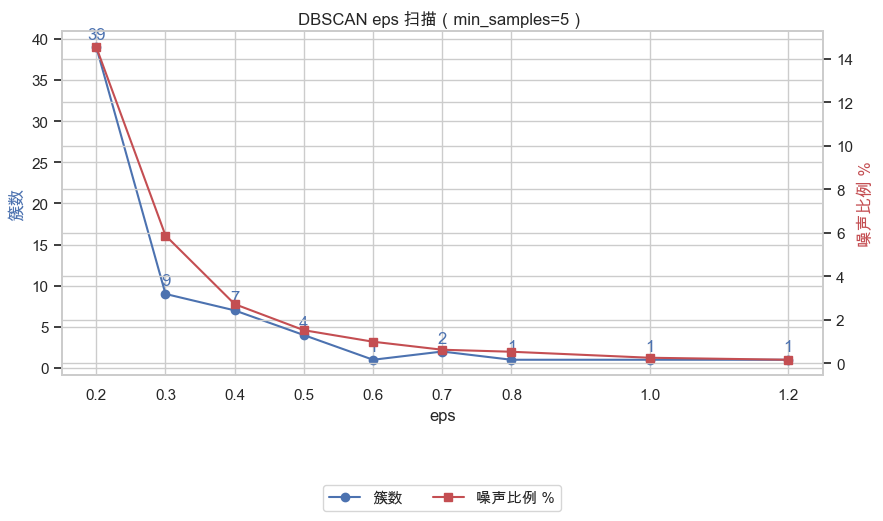

In [31]:
# ========== 附录：DBSCAN eps 参数扫描 ==========
eps_grid = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2]  # 候选 eps 列表
n_clus_g, noise_g = [], []  # 分别存每个 eps 的「簇数」与「噪声比例%」
for e in eps_grid:
    db = DBSCAN(eps=e, min_samples=MIN_PTS).fit(X_scaled)  # 用当前 eps 训练
    labs = db.labels_
    n_clus_g.append(len(set(labs)) - (1 if -1 in labs else 0))  # 簇数（含噪声 -1 时减掉）
    noise_g.append((labs == -1).mean() * 100)  # True 的均值 = 噪声占比，乘 100 变成百分数

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(eps_grid, n_clus_g, marker="o", color="#4C72B0", label="簇数")
ax1.set_xlabel("eps"); ax1.set_ylabel("簇数", color="#4C72B0")
ax1.set_xticks(eps_grid)  # 横轴刻度固定为候选 eps 列表
for e, nc in zip(eps_grid, n_clus_g):  # 在每个数据点上方标注簇数
    ax1.annotate(f"{nc}", (e, nc), textcoords="offset points", xytext=(0, 6), ha="center", color="#4C72B0")
ax2 = ax1.twinx()  # 双轴：右侧轴画噪声比例
ax2.plot(eps_grid, noise_g, marker="s", color="#C44E52", label="噪声比例 %")
ax2.set_ylabel("噪声比例 %", color="#C44E52")
ax1.set_title(f"DBSCAN eps 扫描（min_samples={MIN_PTS}）")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.tight_layout()
plt.show()

**读图与解读**：
- 实测：eps=0.2 → **39 个碎片簇 + 14.5% 噪声**；eps=0.5 → 4 簇；eps=0.6 → **塌缩成 1 簇**；eps≥0.8 恒为 1 簇。
- 曲线**没有稳定平台**：eps 略调小就碎成几十个微簇、略调大就全部连通 → 说明 RFM 空间**密度均匀连续、无高/低密度分界**，这是 DBSCAN 最不擅长的情况（它擅长环形/月牙形等密度分离数据）。
- 客户 RFM 是连续渐变的层级分布，用**质心类算法（K-means / GMM）**更合适；DBSCAN 在 3 维标准化空间难以找到合理参数，当前结果（1 簇）不可用。
- 若想再救 DBSCAN：换 HDBSCAN（自动选 eps）或在 PCA 降维后跑，但预期收益有限，不作为主线。

### 11.7 业务散点：Recency × Monetary

把标准化空间的分群翻译回**业务坐标**（Monetary 用 log 轴），看每个簇落在哪个商业象限。

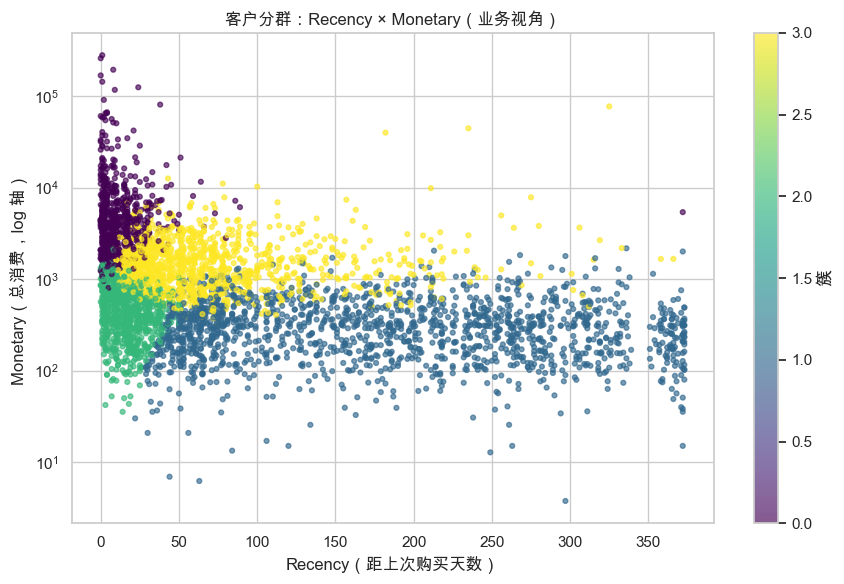

In [32]:
# ========== 业务视角的最终分群图 ==========
fig, ax = plt.subplots(figsize=(9, 6))
# 用原始（未 log）的 Recency 与 Monetary 画散点，按簇号上色，直观对应业务含义
sc = ax.scatter(rfm["Recency"], rfm["Monetary"], c=rfm["Cluster_KM"], cmap="viridis", s=12, alpha=0.65)
ax.set_yscale("log")  # 纵轴用对数刻度（Monetary 跨度太大，log 轴才能看清整体结构）
ax.set_xlabel("Recency（距上次购买天数）"); ax.set_ylabel("Monetary（总消费，log 轴）")
fig.colorbar(sc, ax=ax, label="簇")
ax.set_title("客户分群：Recency × Monetary（业务视角）")
plt.tight_layout()
plt.show()

**读图**：
- **左上（活跃 + 高消费）**= 簇0，重点维护对象（权益、交叉销售）；**右上（高消费但流失）**= 高价值流失风险客户，应优先召回。
- **左下（刚买但花得少）**= 簇2 新客/低频，需要促复购；**右下（长期没来且花得少）**= 簇1 沉睡，占 38%，价值低，营销投入需谨慎。
- 图上簇之间是**连续过渡**而非明显断裂 → 呼应 11.1「轮廓系数中等」的结论。

### 11.8 局限性与改进方向

**已知局限**：
1. **轮廓系数中等（0.337）**：RFM 分布连续、簇边界模糊，K=4 是「折中」而非「清晰结构」。
2. **DBSCAN 失效**：RFM 密度均匀无密度分离结构，eps 扫描（11.6）证实，当前 DBSCAN 结果不可用。
3. **极端值影响**：Monetary 均值 2,049 / 中位数 669 / 最大 28 万，少数大客户可能单点支配簇中心（已 log1p 缓解，未根治）。
4. **数据右截断**：观察窗口止于 2011-12-09，Recency 上限 373 天——「沉睡」客户可能被低估（真实可能更久没来）。
5. **单一市场**：英国占比约 89%（非空 ID 交易行口径；4,338 客户口径为 90.4%），分群主要刻画英国客户，外推需谨慎。
6. **数据口径（已从头重跑核对一致）**：清洗链路 541,909 → 剔除脏数据 397,884 → 去重 392,692，与 3.8 小结及本报告全部数字吻合。唯一注意点：3.7「初步视角」输出 397,924 行 / 4,339 客户**仅剔除 CustomerID 缺失与 C 单**，还含 40 行 `UnitPrice=0`（31 个客户），与清洗后 397,884 / 4,338 相差 40 行 / 1 客户——两者口径不同但均正确，引用请注明口径。

**改进方向（按优先级）**：
1. **特征扩展**：加入行级聚合特征——独特商品数（品类多样性）、平均客单价、订单间隔标准差、退货/取消率。RFM 只有 3 维，信息有限是轮廓系数上不去的主因。
2. **换算法**：GMM（软聚类，能表达「渐变」本质，用 BIC 选分量数）或 HDBSCAN。
3. **极端值处理**：对 Monetary 做 Winsorize（如 99 分位截断）后重跑，检验簇画像稳健性。
4. **K 再验证**：把 K=3/5/6 的画像也跑出来对比业务解释力（当前只选了 K=4）。
5. **业务验证**：与 RFM 经典分箱（R/F/M 各 5 档）交叉验证，确认簇标签业务上说得通。
6. **时间外推验证**：数据仅覆盖 2010-12 ~ 2011-12 一年窗口，分群结论对窗口外时间的稳健性未验证；若取得更长周期数据，可用前半段聚类、后半段核对跨期 ARI / 簇占比漂移。
7. **特征相关性（可选）**：Frequency 与 Monetary 强相关（买得勤通常花得多），欧氏距离会重复计入重叠信息；可对 RFM 先做 PCA 去相关后聚类，观察轮廓系数变化。